In [1]:
import kagglehub
path = kagglehub.dataset_download("atulyakumar98/pothole-detection-dataset")
print("✅ Data source import complete.")

100%|██████████| 194M/194M [00:01<00:00, 132MB/s]

Extracting files...


✅ Data source import complete.


In [2]:
import os
downloaded_files = os.listdir(path)
print("Downloaded files:")
for file in downloaded_files:
    print(file)

Downloaded files:
potholes
normal


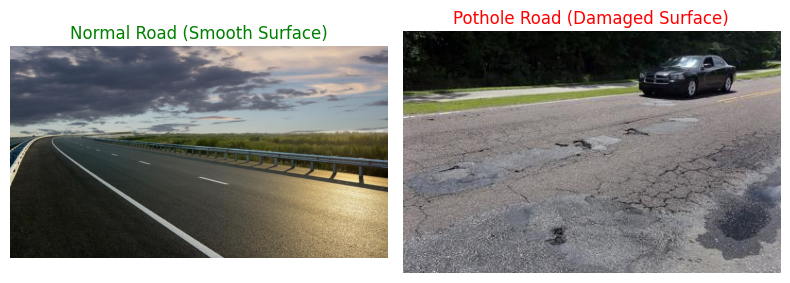

In [4]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
import os

# Define category paths
normal_path = os.path.join(path,"normal")
potholes_path = os.path.join(path,"potholes")

# Randomly select one sample image from each class
sample_normal = random.choice(os.listdir(normal_path))
sample_potholes = random.choice(os.listdir(potholes_path))

# Plot the selected samples
plt.figure(figsize=(8, 4))

# Normal road
plt.subplot(1, 2, 1)
plt.imshow(mpimg.imread(os.path.join(normal_path, sample_normal)))
plt.title("Normal Road (Smooth Surface)", fontsize=12, color='green')
plt.axis('off')

# Pothole road
plt.subplot(1, 2, 2)
plt.imshow(mpimg.imread(os.path.join(potholes_path, sample_potholes)))
plt.title("Pothole Road (Damaged Surface)", fontsize=12, color='red')
plt.axis('off')

plt.tight_layout()
plt.show()


In [5]:
import os
import shutil
import random
from sklearn.model_selection import train_test_split

# ✅ Path to your main dataset
base_dir = path # Corrected to use the full path from samples_path

# ✅ Output directories
train_dir = "road_train"
val_dir = "road_val"
test_dir = "road_test"

# ✅ Split ratios
train_ratio = 0.7
val_ratio = 0.15
test_ratio = 0.15

# ✅ Create directories
for folder in [train_dir, val_dir, test_dir]:
    os.makedirs(folder, exist_ok=True)

# ✅ Split and copy images
for category in os.listdir(base_dir):
    category_path = os.path.join(base_dir, category)
    if os.path.isdir(category_path):
        images = os.listdir(category_path)
        random.shuffle(images)

        # Split 70/15/15
        train_files, temp_files = train_test_split(images, test_size=(1 - train_ratio), random_state=42)
        val_files, test_files = train_test_split(temp_files, test_size=(test_ratio / (test_ratio + val_ratio)), random_state=42)

        # Create subfolders
        for folder, files in zip([train_dir, val_dir, test_dir], [train_files, val_files, test_files]):
            os.makedirs(os.path.join(folder, category), exist_ok=True)
            for file in files:
                shutil.copy(os.path.join(category_path, file), os.path.join(folder, category, file))

print("✅ Dataset successfully split into Train, Validation, and Test folders!")

✅ Dataset successfully split into Train, Validation, and Test folders!


In [6]:
def count_images(directory):
    print(f"\n📁 Dataset Summary for: {directory}")
    total = 0
    for category in os.listdir(directory):
        category_path = os.path.join(directory, category)
        if os.path.isdir(category_path):
            count = len(os.listdir(category_path))
            total += count
            print(f"  {category}: {count} images")
    print(f"  ➤ Total images: {total}")

count_images(train_dir)
count_images(val_dir)
count_images(test_dir)


📁 Dataset Summary for: road_train
  potholes: 230 images
  normal: 246 images
  ➤ Total images: 476

📁 Dataset Summary for: road_val
  potholes: 49 images
  normal: 53 images
  ➤ Total images: 102

📁 Dataset Summary for: road_test
  potholes: 50 images
  normal: 53 images
  ➤ Total images: 103


In [7]:
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
from PIL import Image

# ✅ Paths
train_dir = "road_train"
augmented_dir = "road_train_augmented"

# ✅ Create output directory
os.makedirs(augmented_dir, exist_ok=True)

# ✅ Define augmentation settings
datagen = ImageDataGenerator(
    rotation_range=25,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# ✅ Loop through each class folder
for category in os.listdir(train_dir):
    category_path = os.path.join(train_dir, category)
    save_path = os.path.join(augmented_dir, category)
    os.makedirs(save_path, exist_ok=True)

    images = os.listdir(category_path)
    print(f"\n🔄 Augmenting class: {category} ({len(images)} original images)")

    for img_name in images:
        img_path = os.path.join(category_path, img_name)
        img = Image.open(img_path).convert("RGB")
        img_array = np.expand_dims(np.array(img), 0)

        # Generate and save 4 augmented versions per image
        aug_iter = datagen.flow(img_array, batch_size=1, save_to_dir=save_path,
                                save_prefix="aug", save_format="jpg")

        for i in range(4):  # number of augmented images per original
            next(aug_iter)

print("\n✅ Augmentation complete! Augmented images saved to 'road_train_augmented'")


🔄 Augmenting class: potholes (230 original images)

🔄 Augmenting class: normal (246 original images)

✅ Augmentation complete! Augmented images saved to 'road_train_augmented'


In [8]:
def count_images(directory):
    print(f"\n📁 Dataset Summary for: {directory}")
    total = 0
    for category in os.listdir(directory):
        category_path = os.path.join(directory, category)
        if os.path.isdir(category_path):
            count = len(os.listdir(category_path))
            total += count
            print(f"  {category}: {count} images")
    print(f"  ➤ Total images: {total}")

count_images(augmented_dir)



📁 Dataset Summary for: road_train_augmented
  potholes: 871 images
  normal: 935 images
  ➤ Total images: 1806


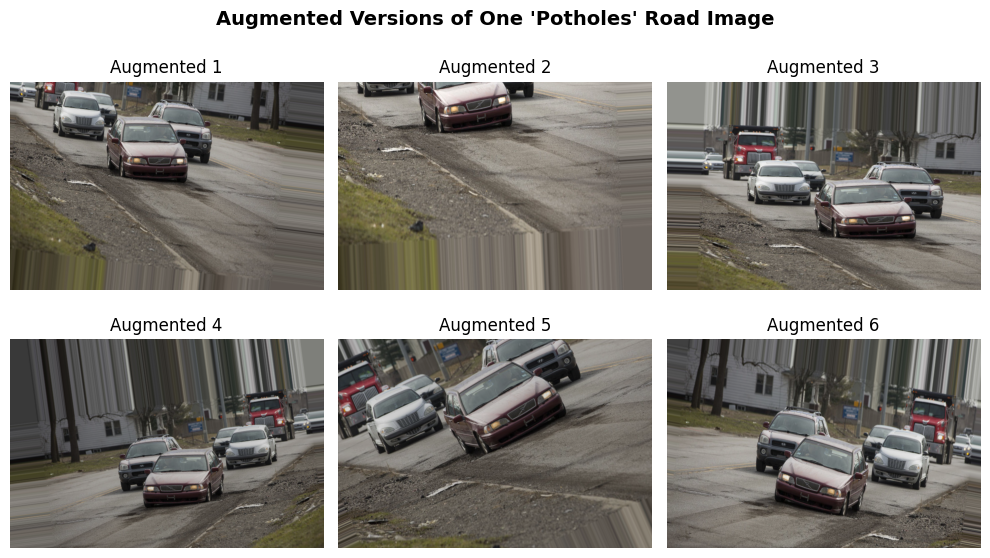

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img

# ✅ Choose one sample image (example: from 'poor' category)
sample_image_path = "road_train/potholes"
sample_file = os.listdir(sample_image_path)[5]
img_path = os.path.join(sample_image_path, sample_file)

# ✅ Load the image
img = load_img(img_path)
x = img_to_array(img)
x = np.expand_dims(x, axis=0)

# ✅ Define augmentation generator
datagen = ImageDataGenerator(
    rotation_range=25,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# ✅ Generate and show 6 augmented versions
plt.figure(figsize=(10, 6))
i = 0
for batch in datagen.flow(x, batch_size=1):
    plt.subplot(2, 3, i + 1)
    plt.imshow(batch[0] / 255.0)
    plt.axis('off')
    plt.title(f"Augmented {i+1}")
    i += 1
    if i == 6:  # show 6 augmented examples
        break

plt.suptitle("Augmented Versions of One 'Potholes' Road Image", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [12]:
import shutil, os

# Paths
train_dir = "road_train"
aug_dir = "road_train_augmented"
combined_dir = "road_train_combined"

os.makedirs(combined_dir, exist_ok=True)

for cls in os.listdir(train_dir):
    os.makedirs(os.path.join(combined_dir, cls), exist_ok=True)

    # Copy original images
    for img in os.listdir(os.path.join(train_dir, cls)):
        shutil.copy(os.path.join(train_dir, cls, img), os.path.join(combined_dir, cls, img))

    # Copy augmented images
    for img in os.listdir(os.path.join(aug_dir, cls)):
        shutil.copy(os.path.join(aug_dir, cls, img), os.path.join(combined_dir, cls, f"aug_{img}"))


In [13]:
import os

for folder in ['road_train_combined', 'road_val', 'road_test']:
    print(f"\n📁 Dataset Summary for: {folder}")
    total = 0
    for cls in os.listdir(folder):
        count = len(os.listdir(os.path.join(folder, cls)))
        print(f"  {cls}: {count} images")
        total += count
    print(f"  ➤ Total images: {total}")



📁 Dataset Summary for: road_train_combined
  potholes: 1101 images
  normal: 1181 images
  ➤ Total images: 2282

📁 Dataset Summary for: road_val
  potholes: 49 images
  normal: 53 images
  ➤ Total images: 102

📁 Dataset Summary for: road_test
  potholes: 50 images
  normal: 53 images
  ➤ Total images: 103


In [14]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import os

# ================================
# 📁 Paths
# ================================
train_dir = "road_train_combined"   # change to your folder name if different
val_dir = "road_val"
test_dir = "road_test"

# ================================
# ⚙️ Image size and batch
# ================================
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# ================================
# 🔄 Data Generators with Augmentation
# ================================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'  # ✅ only 2 classes now
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# ================================
# 🧠 CNN Model (Simplified for Binary Classification)
# ================================
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dropout(0.4),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')  # ✅ output for binary classification
])

# ================================
# ⚙️ Compile Model
# ================================
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

# ================================
# 🚀 Train Model
# ================================
history = model.fit(train_gen, validation_data=val_gen, epochs=15, verbose=1)

# ================================
# 📊 Evaluate on Test Data
# ================================
test_loss, test_acc = model.evaluate(test_gen)
print(f"\n✅ Test Accuracy: {test_acc * 100:.2f}%")

# ================================
# 💾 Save Model
# ================================
model.save("road_condition_cnn_binary.keras")
print("💾 Model saved successfully as road_condition_cnn_binary.keras!")


Found 2282 images belonging to 2 classes.
Found 102 images belonging to 2 classes.
Found 103 images belonging to 2 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,686,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,705,921 (14.14 MB)

 Trainable params: 3,705,921 (14.14 MB)

 Non-trainable params: 0 (0.00 B)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 34s 393ms/step - accuracy: 0.5999 - loss: 0.7317 - val_accuracy: 0.7843 - val_loss: 0.3841
Epoch 2/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 26s 359ms/step - accuracy: 0.8426 - loss: 0.3555 - val_accuracy: 0.8529 - val_loss: 0.4351
Epoch 3/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 25s 344ms/step - accuracy: 0.8878 - loss: 0.2730 - val_accuracy: 0.8431 - val_loss: 0.3298
Epoch 4/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 25s 335ms/step - accuracy: 0.8932 - loss: 0.2847 - val_accuracy: 0.8333 - val_loss: 0.4169
Epoch 5/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 25s 344ms/step - accuracy: 0.8923 - loss: 0.2477 - val_accuracy: 0.8529 - val_loss: 0.3729
Epoch 6/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 25s 351ms/step - accuracy: 0.8962 - loss: 0.2501 - val_accuracy: 0.9118 - val_loss: 0.2077
Epoch 7/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 25s 347ms/step - accuracy: 0.9233 - loss: 0.2064 - val_accuracy: 0.8333 - val_loss: 0.3292
Epoch 8/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 25s 344ms/step - accuracy: 0.8958 - loss: 0.2461 - val_accu

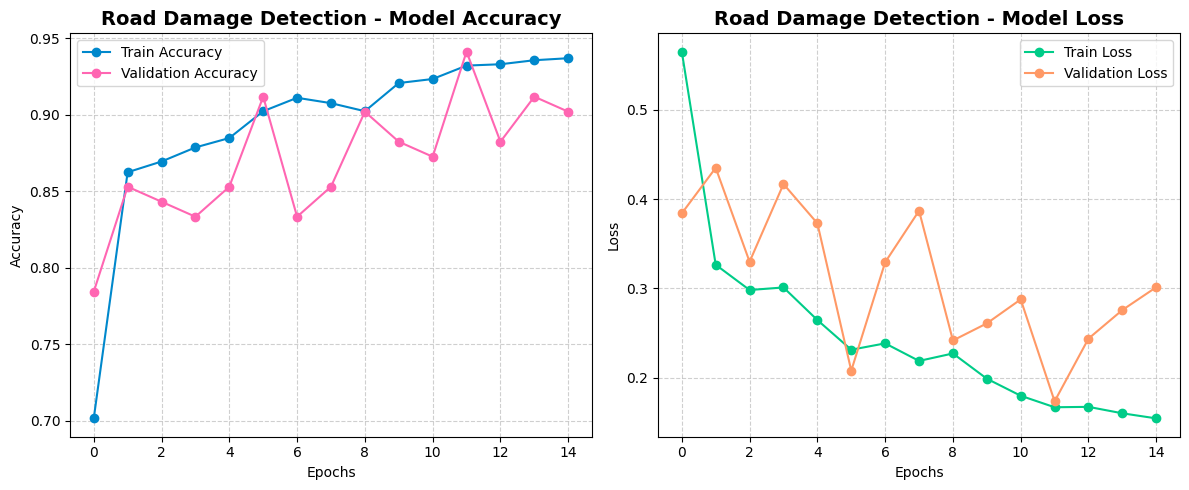

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# =========================
# 1️⃣ Plot Training Curves
# =========================
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='#0088cc', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='#ff66b2', marker='o')
plt.title("Road Damage Detection - Model Accuracy", fontsize=14, weight='bold')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='#00cc88', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', color='#ff9966', marker='o')
plt.title("Road Damage Detection - Model Loss", fontsize=14, weight='bold')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 396ms/step


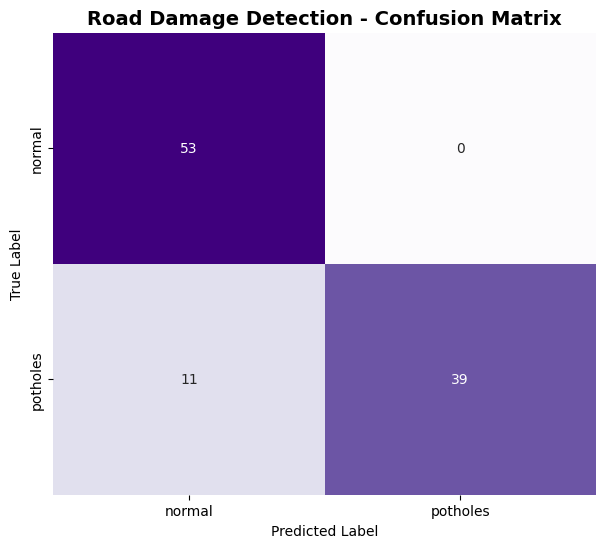


Classification Report:
              precision    recall  f1-score   support

      normal       0.83      1.00      0.91        53
    potholes       1.00      0.78      0.88        50

    accuracy                           0.89       103
   macro avg       0.91      0.89      0.89       103
weighted avg       0.91      0.89      0.89       103



In [16]:
class_labels = ['normal', 'potholes'] # Corrected class labels to match directory names
# Predict on test data
y_pred_proba = model.predict(test_gen)
y_pred = (y_pred_proba > 0.5).astype(int) # Convert probabilities to binary predictions
y_true = test_gen.classes

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=class_labels, yticklabels=class_labels, cbar=False)
plt.title("Road Damage Detection - Confusion Matrix", fontsize=14, weight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_labels))

In [17]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# ================================+
# 📁 Paths (Using the combined_dir for training)
# ================================+
train_dir_tl = "road_train_combined" # Use the combined augmented data
val_dir_tl = "road_val"
test_dir_tl = "road_test"

# ================================+
# ⚙️ Image size and batch
# ================================+
IMG_SIZE_TL = (224, 224) # MobileNetV2 expects 224x224 input
BATCH_SIZE_TL = 32
EPOCHS_TL = 15 # Increased epochs for transfer learning

# ================================+
# 🔄 Data Generators for Transfer Learning
# ================================+
train_datagen_tl = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen_tl = ImageDataGenerator(rescale=1./255)
test_datagen_tl = ImageDataGenerator(rescale=1./255)

train_gen_tl = train_datagen_tl.flow_from_directory(
    train_dir_tl,
    target_size=IMG_SIZE_TL,
    batch_size=BATCH_SIZE_TL,
    class_mode='binary'
)

val_gen_tl = val_datagen_tl.flow_from_directory(
    val_dir_tl,
    target_size=IMG_SIZE_TL,
    batch_size=BATCH_SIZE_TL,
    class_mode='binary'
)

test_gen_tl = test_datagen_tl.flow_from_directory(
    test_dir_tl,
    target_size=IMG_SIZE_TL,
    batch_size=BATCH_SIZE_TL,
    class_mode='binary',
    shuffle=False # Keep data in order for evaluation
)

# ================================+
# 🧠 Build Transfer Learning Model
# ================================+
# Load MobileNetV2 pre-trained on ImageNet, without the top classification layer
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE_TL[0], IMG_SIZE_TL[1], 3))

# Freeze the base model layers
base_model.trainable = False

# Add custom classification layers on top of the base model
x = base_model.output
x = GlobalAveragePooling2D()(x) # Convert feature maps to a single vector per image
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x) # Add dropout for regularization
predictions = Dense(1, activation='sigmoid')(x) # Output layer for binary classification

model_tl = Model(inputs=base_model.input, outputs=predictions)

# ================================+
# ⚙️ Compile Model
# ================================+
model_tl.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
model_tl.summary()

# ================================+
# 🚀 Train Model (Fine-tuning new layers)
# ================================+
print("\n--- Training custom head layers ---")
history_tl = model_tl.fit(
    train_gen_tl,
    epochs=EPOCHS_TL,
    validation_data=val_gen_tl,
    verbose=1
)

# ================================+
# 💾 Save Model
# ================================+
model_tl.save("road_condition_mobilenetv2.keras")
print("\n💾 Transfer Learning Model saved successfully as road_condition_mobilenetv2.keras!")


Found 2282 images belonging to 2 classes.
Found 102 images belonging to 2 classes.
Found 103 images belonging to 2 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


--- Training custom head layers ---


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 82s 910ms/step - accuracy: 0.8636 - loss: 0.3360 - val_accuracy: 0.9608 - val_loss: 0.1094
Epoch 2/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 41s 572ms/step - accuracy: 0.9467 - loss: 0.1360 - val_accuracy: 0.9706 - val_loss: 0.1010
Epoch 3/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 41s 565ms/step - accuracy: 0.9597 - loss: 0.1125 - val_accuracy: 0.9706 - val_loss: 0.1113
Epoch 4/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 40s 560ms/step - accuracy: 0.9595 - loss: 0.0987 - val_accuracy: 0.9706 - val_loss: 0.1300
Epoch 5/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 41s 575ms/step - accuracy: 0.9666 - loss: 0.0978 - val_accuracy: 0.9608 - val_loss: 0.1107
Epoch 6/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 81s 566ms/step - accuracy: 0.9835 - loss: 0.0577 - val_accuracy: 0.9706 - val_loss: 0.1147
Epoch 7/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 41s 561ms/step - accuracy: 0.9687 - loss: 0.0710 - val_accuracy: 0.9608 - val_loss: 0.1506
Epoch 8/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 40s 563ms/step - accuracy: 0.9709 - loss: 0.0804 - val_accu

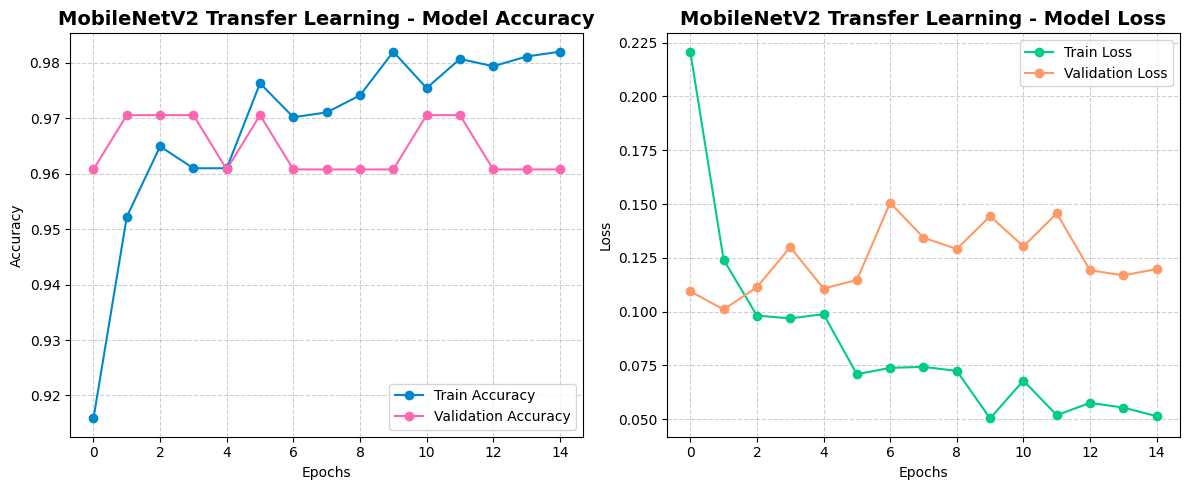

4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 4s/step - accuracy: 0.9657 - loss: 0.1009

✅ Test Accuracy (Transfer Learning Model): 96.12%
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step


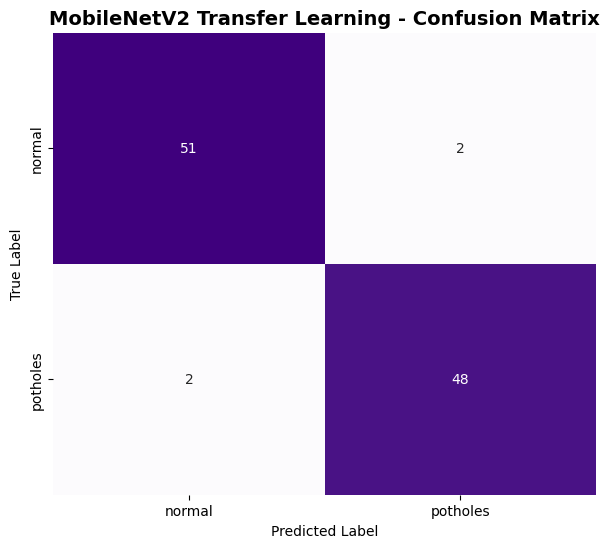


Classification Report (Transfer Learning Model):
              precision    recall  f1-score   support

      normal       0.96      0.96      0.96        53
    potholes       0.96      0.96      0.96        50

    accuracy                           0.96       103
   macro avg       0.96      0.96      0.96       103
weighted avg       0.96      0.96      0.96       103



In [18]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# =========================
# 1️⃣ Plot Training Curves
# =========================
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history_tl.history['accuracy'], label='Train Accuracy', color='#0088cc', marker='o')
plt.plot(history_tl.history['val_accuracy'], label='Validation Accuracy', color='#ff66b2', marker='o')
plt.title("MobileNetV2 Transfer Learning - Model Accuracy", fontsize=14, weight='bold')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history_tl.history['loss'], label='Train Loss', color='#00cc88', marker='o')
plt.plot(history_tl.history['val_loss'], label='Validation Loss', color='#ff9966', marker='o')
plt.title("MobileNetV2 Transfer Learning - Model Loss", fontsize=14, weight='bold')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# ================================+
# 📊 Evaluate on Test Data
# ================================+
test_loss_tl, test_acc_tl = model_tl.evaluate(test_gen_tl)
print(f"\n✅ Test Accuracy (Transfer Learning Model): {test_acc_tl * 100:.2f}%")

# ================================+
# 📈 Confusion Matrix and Classification Report
# ================================+
class_labels_tl = list(test_gen_tl.class_indices.keys())

y_pred_proba_tl = model_tl.predict(test_gen_tl)
y_pred_tl = (y_pred_proba_tl > 0.5).astype(int)
y_true_tl = test_gen_tl.classes

cm_tl = confusion_matrix(y_true_tl, y_pred_tl)

plt.figure(figsize=(7,6))
sns.heatmap(cm_tl, annot=True, fmt='d', cmap='Purples',
            xticklabels=class_labels_tl, yticklabels=class_labels_tl, cbar=False)
plt.title("MobileNetV2 Transfer Learning - Confusion Matrix", fontsize=14, weight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

print("\nClassification Report (Transfer Learning Model):")
print(classification_report(y_true_tl, y_pred_tl, target_names=class_labels_tl))


In [19]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# ================================
# ➔ Paths (Using the combined_dir for training)
# ================================
train_dir_vgg = "road_train_combined" # Use the combined augmented data
val_dir_vgg = "road_val"
test_dir_vgg = "road_test"

# ================================
# ⚙♣♢ Image size and batch
# ================================
IMG_SIZE_VGG = (224, 224) # VGG16 expects 224x224 input
BATCH_SIZE_VGG = 32
EPOCHS_VGG = 15 # Increased epochs for transfer learning

# ================================
# ↶ Data Generators for Transfer Learning
# ================================
train_datagen_vgg = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen_vgg = ImageDataGenerator(rescale=1./255)
test_datagen_vgg = ImageDataGenerator(rescale=1./255)

train_gen_vgg = train_datagen_vgg.flow_from_directory(
    train_dir_vgg,
    target_size=IMG_SIZE_VGG,
    batch_size=BATCH_SIZE_VGG,
    class_mode='binary'
)

val_gen_vgg = val_datagen_vgg.flow_from_directory(
    val_dir_vgg,
    target_size=IMG_SIZE_VGG,
    batch_size=BATCH_SIZE_VGG,
    class_mode='binary'
)

test_gen_vgg = test_datagen_vgg.flow_from_directory(
    test_dir_vgg,
    target_size=IMG_SIZE_VGG,
    batch_size=BATCH_SIZE_VGG,
    class_mode='binary',
    shuffle=False # Keep data in order for evaluation
)

# ================================
# ≌ Build Transfer Learning Model (VGG16)
# ================================
# Load VGG16 pre-trained on ImageNet, without the top classification layer
base_model_vgg = VGG16(weights='imagenet', include_top=False, input_shape=(IMG_SIZE_VGG[0], IMG_SIZE_VGG[1], 3))

# Freeze the base model layers
base_model_vgg.trainable = False

# Add custom classification layers on top of the base model
x = base_model_vgg.output
x = GlobalAveragePooling2D()(x) # Convert feature maps to a single vector per image
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x) # Add dropout for regularization
predictions = Dense(1, activation='sigmoid')(x) # Output layer for binary classification

model_vgg = Model(inputs=base_model_vgg.input, outputs=predictions)

# ================================
# ⚙♣♢ Compile Model
# ================================
model_vgg.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
model_vgg.summary()

# ================================
# ↗ Train Model (Fine-tuning new layers)
# ================================
print("\n--- Training custom head layers for VGG16 ---")
history_vgg = model_vgg.fit(
    train_gen_vgg,
    epochs=EPOCHS_VGG,
    validation_data=val_gen_vgg,
    verbose=1
)

# ================================
# ↓ Save Model
# ================================
model_vgg.save("road_condition_vgg16.keras")
print("\n↓ VGG16 Transfer Learning Model saved successfully as road_condition_vgg16.keras!")

Found 2282 images belonging to 2 classes.
Found 102 images belonging to 2 classes.
Found 103 images belonging to 2 classes.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)


--- Training custom head layers for VGG16 ---


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 70s 755ms/step - accuracy: 0.7069 - loss: 0.5810 - val_accuracy: 0.9608 - val_loss: 0.2533
Epoch 2/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 44s 609ms/step - accuracy: 0.9118 - loss: 0.2883 - val_accuracy: 0.9608 - val_loss: 0.1499
Epoch 3/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 45s 622ms/step - accuracy: 0.9266 - loss: 0.2084 - val_accuracy: 0.9804 - val_loss: 0.0975
Epoch 4/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 44s 604ms/step - accuracy: 0.9391 - loss: 0.1723 - val_accuracy: 0.9608 - val_loss: 0.1143
Epoch 5/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 51s 712ms/step - accuracy: 0.9333 - loss: 0.1644 - val_accuracy: 0.9804 - val_loss: 0.0770
Epoch 6/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 52s 720ms/step - accuracy: 0.9420 - loss: 0.1560 - val_accuracy: 0.9804 - val_loss: 0.0540
Epoch 7/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 44s 606ms/step - accuracy: 0.9437 - loss: 0.1537 - val_accuracy: 0.9804 - val_loss: 0.0480
Epoch 8/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 46s 622ms/step - accuracy: 0.9564 - loss: 0.1287 - val_accu

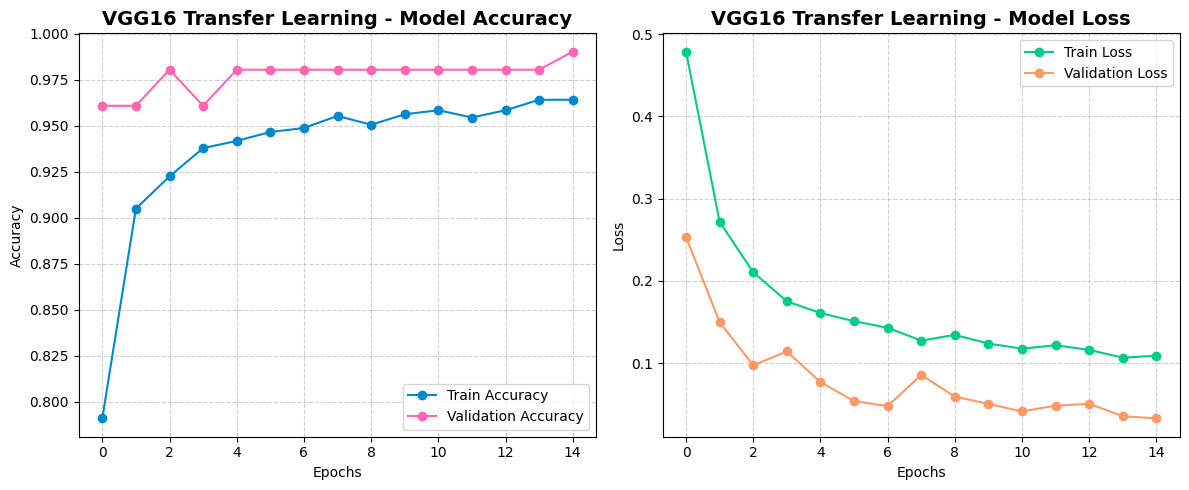

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.9262 - loss: 0.1609

✅ Test Accuracy (VGG16 Transfer Learning Model): 92.23%


3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 568ms/step


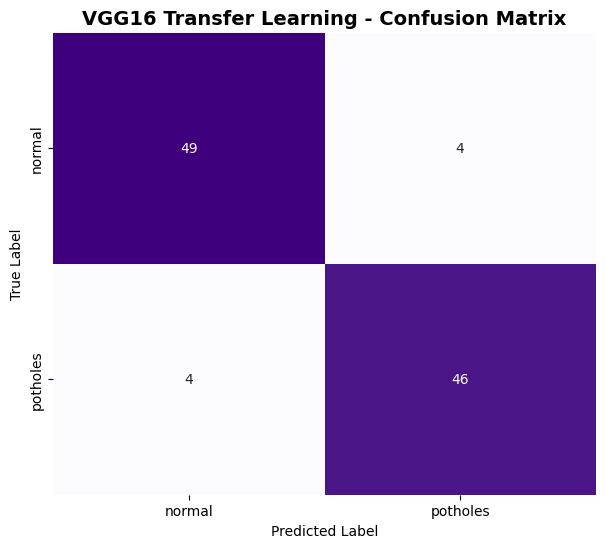


Classification Report (VGG16 Transfer Learning Model):
              precision    recall  f1-score   support

      normal       0.92      0.92      0.92        53
    potholes       0.92      0.92      0.92        50

    accuracy                           0.92       103
   macro avg       0.92      0.92      0.92       103
weighted avg       0.92      0.92      0.92       103



In [20]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# =========================
# 1⏰ Plot Training Curves
# =========================
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history_vgg.history['accuracy'], label='Train Accuracy', color='#0088cc', marker='o')
plt.plot(history_vgg.history['val_accuracy'], label='Validation Accuracy', color='#ff66b2', marker='o')
plt.title("VGG16 Transfer Learning - Model Accuracy", fontsize=14, weight='bold')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history_vgg.history['loss'], label='Train Loss', color='#00cc88', marker='o')
plt.plot(history_vgg.history['val_loss'], label='Validation Loss', color='#ff9966', marker='o')
plt.title("VGG16 Transfer Learning - Model Loss", fontsize=14, weight='bold')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# ================================
# 📊 Evaluate on Test Data
# ================================
test_loss_vgg, test_acc_vgg = model_vgg.evaluate(test_gen_vgg)
print(f"\n✅ Test Accuracy (VGG16 Transfer Learning Model): {test_acc_vgg * 100:.2f}%")

# ================================
# 📈 Confusion Matrix and Classification Report
# ================================
class_labels_vgg = list(test_gen_vgg.class_indices.keys())

y_pred_proba_vgg = model_vgg.predict(test_gen_vgg)
y_pred_vgg = (y_pred_proba_vgg > 0.5).astype(int)
y_true_vgg = test_gen_vgg.classes

cm_vgg = confusion_matrix(y_true_vgg, y_pred_vgg)

plt.figure(figsize=(7,6))
sns.heatmap(cm_vgg, annot=True, fmt='d', cmap='Purples',
            xticklabels=class_labels_vgg, yticklabels=class_labels_vgg, cbar=False)
plt.title("VGG16 Transfer Learning - Confusion Matrix", fontsize=14, weight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

print("\nClassification Report (VGG16 Transfer Learning Model):")
print(classification_report(y_true_vgg, y_pred_vgg, target_names=class_labels_vgg))

/tmp/ipython-input-1731138607.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Test Accuracy', data=accuracy_df, palette='viridis')


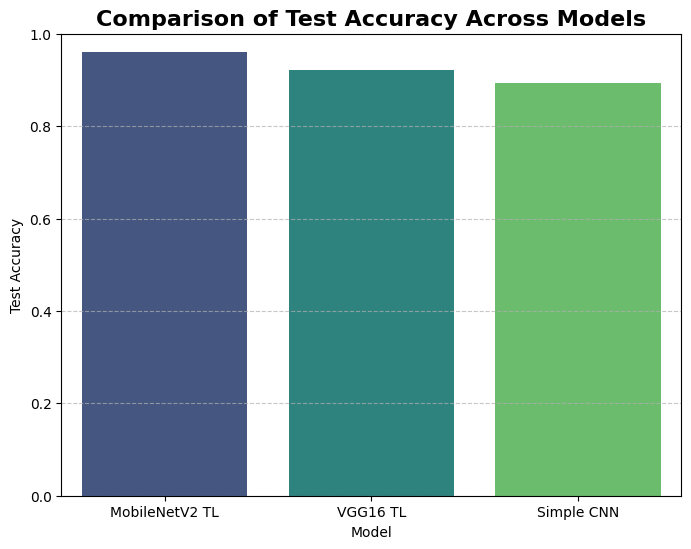

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

# Assuming you have the test accuracy for all three models:
# test_acc (from the first CNN model)
# test_acc_tl (from the MobileNetV2 TL model)
# test_acc_vgg (from the VGG16 TL model)

# Create a dictionary to store the test accuracies
accuracy_data = {
    'Model': ['Simple CNN', 'MobileNetV2 TL', 'VGG16 TL'],
    'Test Accuracy': [test_acc, test_acc_tl, test_acc_vgg]
}

# Create a pandas DataFrame from the dictionary
accuracy_df = pd.DataFrame(accuracy_data)

# Sort the DataFrame by accuracy for better visualization
accuracy_df = accuracy_df.sort_values(by='Test Accuracy', ascending=False)

# Plotting the comparison chart
plt.figure(figsize=(8, 6))
sns.barplot(x='Model', y='Test Accuracy', data=accuracy_df, palette='viridis')
plt.title('Comparison of Test Accuracy Across Models', fontsize=16, weight='bold')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1) # Set y-axis limit from 0 to 1 for accuracy
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

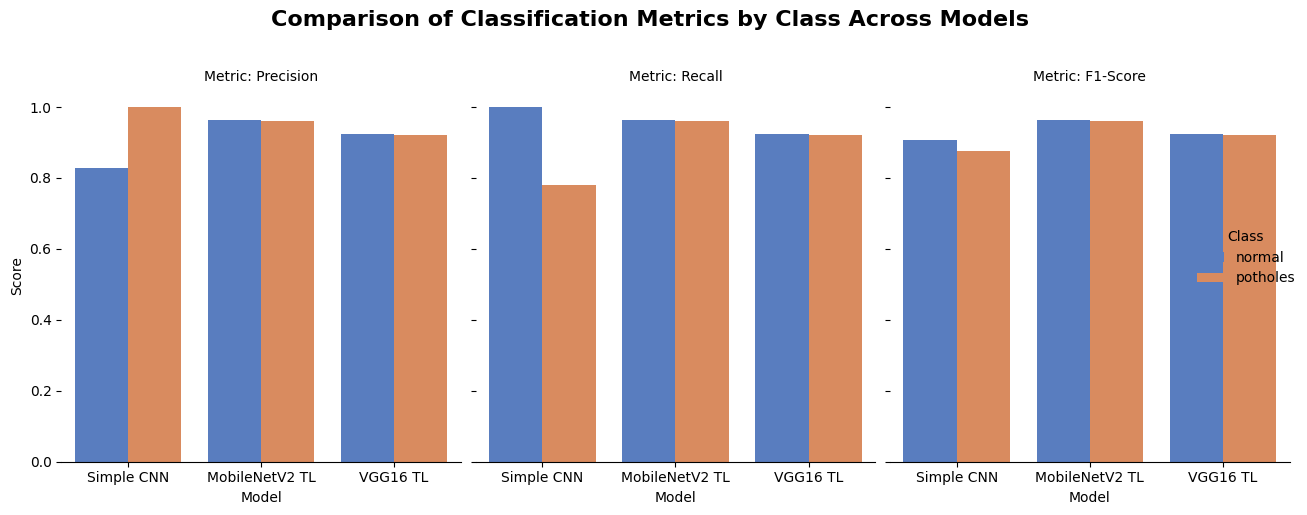

In [29]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Assuming you have the classification reports for all three models
# and the true and predicted labels for the test sets:
# y_true, y_pred (from the first CNN model)
# y_true_tl, y_pred_tl (from the MobileNetV2 TL model)
# y_true_vgg, y_pred_vgg (from the VGG16 TL model)
# class_labels (from the first CNN model, should be ['normal', 'potholes'])
# class_labels_tl (from the MobileNetV2 TL model, should be ['normal', 'potholes'])
# class_labels_vgg (from the VGG16 TL model, should be ['normal', 'potholes'])

# Generate classification reports
report_cnn = classification_report(y_true, y_pred, target_names=class_labels, output_dict=True)
report_mobilenet = classification_report(y_true_tl, y_pred_tl, target_names=class_labels_tl, output_dict=True)
report_vgg16 = classification_report(y_true_vgg, y_pred_vgg, target_names=class_labels_vgg, output_dict=True)

# Extract relevant metrics
metrics_data = {
    'Model': ['Simple CNN', 'Simple CNN', 'MobileNetV2 TL', 'MobileNetV2 TL', 'VGG16 TL', 'VGG16 TL'],
    'Class': ['normal', 'potholes', 'normal', 'potholes', 'normal', 'potholes'],
    'Precision': [report_cnn['normal']['precision'], report_cnn['potholes']['precision'],
                  report_mobilenet['normal']['precision'], report_mobilenet['potholes']['precision'],
                  report_vgg16['normal']['precision'], report_vgg16['potholes']['precision']],
    'Recall': [report_cnn['normal']['recall'], report_cnn['potholes']['recall'],
               report_mobilenet['normal']['recall'], report_mobilenet['potholes']['recall'],
               report_vgg16['normal']['recall'], report_vgg16['potholes']['recall']],
    'F1-Score': [report_cnn['normal']['f1-score'], report_cnn['potholes']['f1-score'],
                 report_mobilenet['normal']['f1-score'], report_mobilenet['potholes']['f1-score'],
                 report_vgg16['normal']['f1-score'], report_vgg16['potholes']['f1-score']]
}

metrics_df = pd.DataFrame(metrics_data)

# Melt the DataFrame for easier plotting with seaborn
metrics_melted = metrics_df.melt(id_vars=['Model', 'Class'], var_name='Metric', value_name='Score')

# Plotting comparison of metrics by class using catplot
g = sns.catplot(x='Model', y='Score', hue='Class', col='Metric', data=metrics_melted, kind='bar', palette='muted', sharey=True, height=5, aspect=.8)
g.fig.suptitle('Comparison of Classification Metrics by Class Across Models', fontsize=16, weight='bold', y=1.02)
g.set_titles("Metric: {col_name}")
g.set_axis_labels("Model", "Score")
g.despine(left=True)
g._legend.set_title("Class") # Set legend title
plt.tight_layout()
plt.show()

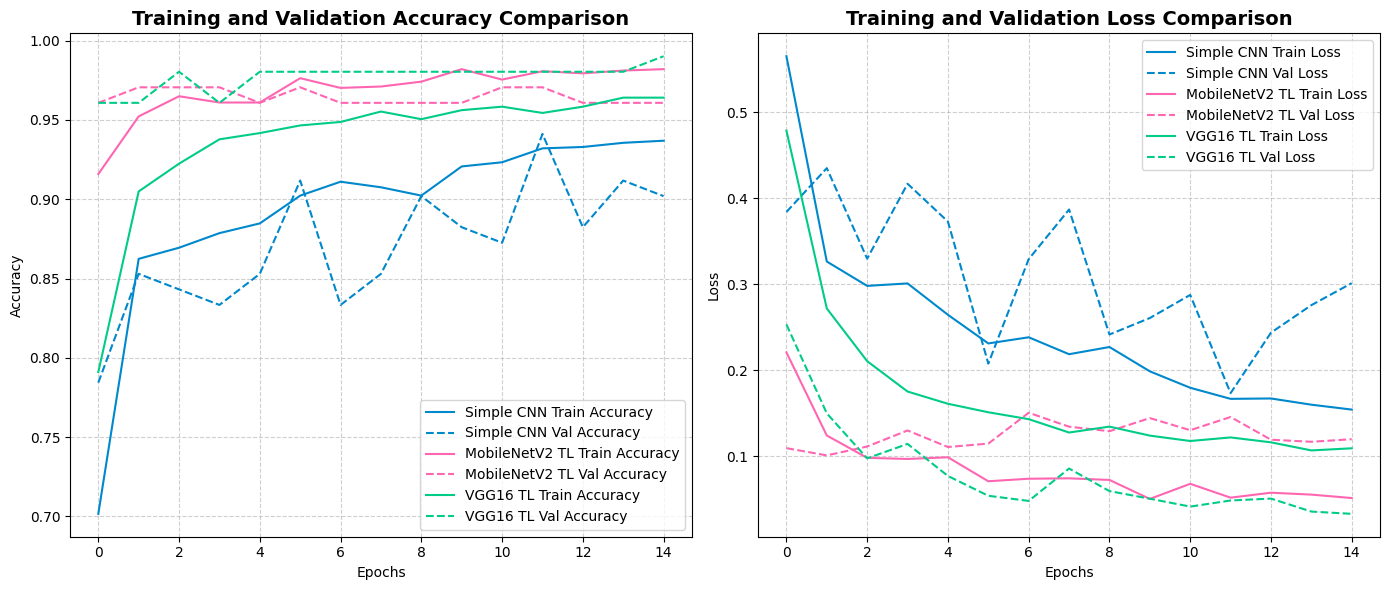

In [26]:
# Assuming you have the history objects from training each model:
# history (from the first CNN model)
# history_tl (from the MobileNetV2 TL model)
# history_vgg (from the VGG16 TL model)

plt.figure(figsize=(14, 6))

# Plotting Training and Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Simple CNN Train Accuracy', color='#0088cc', linestyle='-')
plt.plot(history.history['val_accuracy'], label='Simple CNN Val Accuracy', color='#0088cc', linestyle='--')
plt.plot(history_tl.history['accuracy'], label='MobileNetV2 TL Train Accuracy', color='#ff66b2', linestyle='-')
plt.plot(history_tl.history['val_accuracy'], label='MobileNetV2 TL Val Accuracy', color='#ff66b2', linestyle='--')
plt.plot(history_vgg.history['accuracy'], label='VGG16 TL Train Accuracy', color='#00cc88', linestyle='-')
plt.plot(history_vgg.history['val_accuracy'], label='VGG16 TL Val Accuracy', color='#00cc88', linestyle='--')

plt.title('Training and Validation Accuracy Comparison', fontsize=14, weight='bold')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Plotting Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Simple CNN Train Loss', color='#0088cc', linestyle='-')
plt.plot(history.history['val_loss'], label='Simple CNN Val Loss', color='#0088cc', linestyle='--')
plt.plot(history_tl.history['loss'], label='MobileNetV2 TL Train Loss', color='#ff66b2', linestyle='-')
plt.plot(history_tl.history['val_loss'], label='MobileNetV2 TL Val Loss', color='#ff66b2', linestyle='--')
plt.plot(history_vgg.history['loss'], label='VGG16 TL Train Loss', color='#00cc88', linestyle='-')
plt.plot(history_vgg.history['val_loss'], label='VGG16 TL Val Loss', color='#00cc88', linestyle='--')

plt.title('Training and Validation Loss Comparison', fontsize=14, weight='bold')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

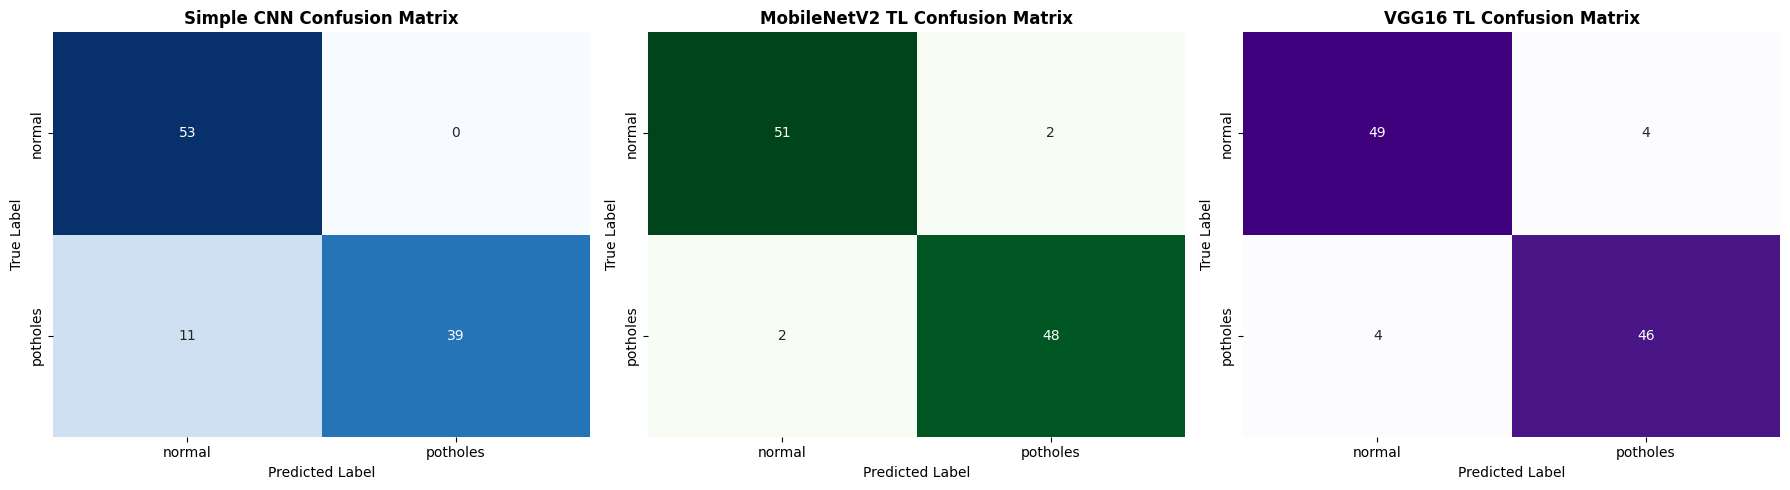

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Assuming you have the true and predicted labels for the test sets:
# y_true, y_pred (from the first CNN model)
# y_true_tl, y_pred_tl (from the MobileNetV2 TL model)
# y_true_vgg, y_pred_vgg (from the VGG16 TL model)
# class_labels (from the first CNN model, should be ['normal', 'potholes'])

# Generate confusion matrices
cm_cnn = confusion_matrix(y_true, y_pred)
cm_mobilenet = confusion_matrix(y_true_tl, y_pred_tl)
cm_vgg16 = confusion_matrix(y_true_vgg, y_pred_vgg)

# Plotting the confusion matrices as heatmaps side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels, ax=axes[0], cbar=False)
axes[0].set_title("Simple CNN Confusion Matrix", fontsize=12, weight='bold')
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(cm_mobilenet, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_labels, yticklabels=class_labels, ax=axes[1], cbar=False)
axes[1].set_title("MobileNetV2 TL Confusion Matrix", fontsize=12, weight='bold')
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

sns.heatmap(cm_vgg16, annot=True, fmt='d', cmap='Purples',
            xticklabels=class_labels, yticklabels=class_labels, ax=axes[2], cbar=False)
axes[2].set_title("VGG16 TL Confusion Matrix", fontsize=12, weight='bold')
axes[2].set_xlabel("Predicted Label")
axes[2].set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [31]:
import tensorflow as tf
import cv2
import numpy as np
from google.colab import files
import os
from IPython.display import display, Javascript
from base64 import b64decode

# ================================
# 1. Upload Video
# ================================
print("Please upload a video file.")
uploaded = files.upload()

if not uploaded:
    print("No file uploaded. Please upload a video to continue.")
else:
    video_filename = list(uploaded.keys())[0]
    print(f"Video '{video_filename}' uploaded successfully.")

    # ================================
    # 2. Load Model
    # ================================
    try:
        model_tl = tf.keras.models.load_model("road_condition_mobilenetv2.keras")
        print("MobileNetV2 model loaded successfully.")
    except Exception as e:
        print(f"Error loading the MobileNetV2 model: {e}")
        model_tl = None # Set model to None if loading fails

    if model_tl:
        # ================================
        # 3. Video Processing Setup
        # ================================
        cap = cv2.VideoCapture(video_filename)

        if not cap.isOpened():
            print(f"Error: Could not open video file {video_filename}")
        else:
            frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            fps = int(cap.get(cv2.CAP_PROP_FPS))
            print(f"Processing video with {frame_count} frames at {fps} FPS.")

            # Get class labels from the generator used during training
            # Assuming the order is the same as the test_gen_tl or train_gen_tl
            class_labels_tl = ['normal', 'potholes'] # Based on your directory structure

            pothole_detected_count = 0
            frame_number = 0
            pothole_alert_given = False # Flag to track if an alert has been given

            print("\n--- Starting Pothole Detection ---")
            # ================================
            # 4. Real-time Pothole Detection and Alerting (Modified)
            # 5. Simulate Reporting (Optional - Modified)
            # 6. Safe Road Alert (Suppressed)
            # ================================
            while cap.isOpened():
                ret, frame = cap.read()
                if not ret:
                    break # End of video

                frame_number += 1

                # Preprocess the frame for the model
                # Ensure the frame has 3 channels (convert grayscale to RGB if necessary)
                if len(frame.shape) == 2:
                    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_GRAY2RGB)
                else:
                    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB) # Convert BGR to RGB

                img = cv2.resize(frame_rgb, (224, 224)) # Resize to model expected input size
                img_array = np.expand_dims(img, axis=0) / 255.0 # Add batch dimension and normalize

                # Make prediction
                prediction = model_tl.predict(img_array, verbose=0) # Set verbose to 0 to reduce output
                predicted_class_index = int(np.round(prediction[0][0])) # Get binary prediction
                predicted_class_label = class_labels_tl[predicted_class_index]

                # Threshold for detection (you might need to adjust this)
                detection_threshold = 0.5 # Assuming 0.5 is the threshold for the sigmoid output

                if predicted_class_label == 'potholes' and prediction[0][0] > detection_threshold:
                    pothole_detected_count += 1

                    # Give alert only on the first detection
                    if not pothole_alert_given:
                        print(f"Frame {frame_number}: Pothole detected! Drive carefully.")
                        # Simulate sending information to authorities
                        print(f"  Simulating report: Pothole image from frame {frame_number} sent to authorities.")
                        pothole_alert_given = True # Set flag to True after the first alert

                # Suppress output for safe frames to avoid clutter

            # Release the video capture object
            cap.release()

            # ================================
            # 9. Summarize Results (Modified)
            # ================================
            print("\n--- Pothole Detection Summary ---")
            if pothole_detected_count > 0:
                print(f"Total potholes detected in the video: {pothole_detected_count}")
            else:
                print("No potholes detected. Smooth road surface throughout the video.")


    # ================================
    # 10. Finish task
    # ================================
    print("\n✅ Pothole detection task complete.")

Please upload a video file.


Saving potholes.mp4 to potholes (1).mp4
Video 'potholes (1).mp4' uploaded successfully.
MobileNetV2 model loaded successfully.
Processing video with 233 frames at 25 FPS.

--- Starting Pothole Detection ---
Frame 1: Pothole detected! Drive carefully.
  Simulating report: Pothole image from frame 1 sent to authorities.

--- Pothole Detection Summary ---
Total potholes detected in the video: 232

✅ Pothole detection task complete.


In [32]:
import tensorflow as tf
import cv2
import numpy as np
from google.colab import files
import os
from IPython.display import display, Javascript
from base64 import b64decode

# ================================
# 1. Upload Video
# ================================
print("Please upload a video file.")
uploaded = files.upload()

if not uploaded:
    print("No file uploaded. Please upload a video to continue.")
else:
    video_filename = list(uploaded.keys())[0]
    print(f"Video '{video_filename}' uploaded successfully.")

    # ================================
    # 2. Load Model
    # ================================
    try:
        model_tl = tf.keras.models.load_model("road_condition_mobilenetv2.keras")
        print("MobileNetV2 model loaded successfully.")
    except Exception as e:
        print(f"Error loading the MobileNetV2 model: {e}")
        model_tl = None # Set model to None if loading fails

    if model_tl:
        # ================================
        # 3. Video Processing Setup
        # ================================
        cap = cv2.VideoCapture(video_filename)

        if not cap.isOpened():
            print(f"Error: Could not open video file {video_filename}")
        else:
            frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            fps = int(cap.get(cv2.CAP_PROP_FPS))
            print(f"Processing video with {frame_count} frames at {fps} FPS.")

            # Get class labels from the generator used during training
            # Assuming the order is the same as the test_gen_tl or train_gen_tl
            class_labels_tl = ['normal', 'potholes'] # Based on your directory structure

            pothole_detected_count = 0
            frame_number = 0
            pothole_alert_given = False # Flag to track if an alert has been given

            print("\n--- Starting Pothole Detection ---")
            # ================================
            # 4. Real-time Pothole Detection and Alerting (Modified)
            # 5. Simulate Reporting (Optional - Modified)
            # 6. Safe Road Alert (Suppressed)
            # ================================
            while cap.isOpened():
                ret, frame = cap.read()
                if not ret:
                    break # End of video

                frame_number += 1

                # Preprocess the frame for the model
                # Ensure the frame has 3 channels (convert grayscale to RGB if necessary)
                if len(frame.shape) == 2:
                    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_GRAY2RGB)
                else:
                    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB) # Convert BGR to RGB

                img = cv2.resize(frame_rgb, (224, 224)) # Resize to model expected input size
                img_array = np.expand_dims(img, axis=0) / 255.0 # Add batch dimension and normalize

                # Make prediction
                prediction = model_tl.predict(img_array, verbose=0) # Set verbose to 0 to reduce output
                predicted_class_index = int(np.round(prediction[0][0])) # Get binary prediction
                predicted_class_label = class_labels_tl[predicted_class_index]

                # Threshold for detection (you might need to adjust this)
                detection_threshold = 0.5 # Assuming 0.5 is the threshold for the sigmoid output

                if predicted_class_label == 'potholes' and prediction[0][0] > detection_threshold:
                    pothole_detected_count += 1

                    # Give alert only on the first detection
                    if not pothole_alert_given:
                        print(f"Frame {frame_number}: Pothole detected! Drive carefully.")
                        # Simulate sending information to authorities
                        print(f"  Simulating report: Pothole image from frame {frame_number} sent to authorities.")
                        pothole_alert_given = True # Set flag to True after the first alert

                # Suppress output for safe frames to avoid clutter

            # Release the video capture object
            cap.release()

            # ================================
            # 9. Summarize Results (Modified)
            # ================================
            print("\n--- Pothole Detection Summary ---")
            if pothole_detected_count > 0:
                print(f"Total potholes detected in the video: {pothole_detected_count}")
            else:
                print("No potholes detected. Smooth road surface throughout the video.")


    # ================================
    # 10. Finish task
    # ================================
    print("\n✅ Pothole detection task complete.")

Please upload a video file.


Saving smooth road.mp4 to smooth road.mp4
Video 'smooth road.mp4' uploaded successfully.
MobileNetV2 model loaded successfully.
Processing video with 338 frames at 29 FPS.

--- Starting Pothole Detection ---

--- Pothole Detection Summary ---
No potholes detected. Smooth road surface throughout the video.

✅ Pothole detection task complete.
